# Reducción de dimensión

Modelos y Simulación II, Universidad de Antioquia. Sección 5 de la guía del proyecto.

Queremos saber si el modelo final se puede simplificar sin perder desempeño. Probamos tres caminos sobre los dos mejores modelos de `02_modelos.ipynb`: quitar variables a partir de un análisis individual (selección), proyectar a componentes principales (PCA, lineal) y proyectar con UMAP (no lineal). Las configuraciones y métricas de los modelos de la sección 4 se leen de `resultados/seccion4.json`, así que hay que ejecutar antes `02_modelos.ipynb`.

Usamos la misma partición, el mismo preprocesamiento y el mismo protocolo de validación de la sección 4: validación cruzada estratificada de 5 pliegues sobre el 80 % de entrenamiento, umbral fijado con predicciones fuera de pliegue y evaluación final en el 20 % de prueba. Ajustamos la reducción (PCA o UMAP) dentro de cada pliegue, después del preprocesamiento.

In [1]:
# En Colab: clonar el repositorio y ejecutar desde su raíz
# !git clone https://github.com/julianGuerra92/modelos-simulacion-2-olist-ml.git
# %cd modelos-simulacion-2-olist-ml
# !pip install -q imbalanced-learn umap-learn

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from umap import UMAP

from olist import datos as D
from olist import evaluacion as E
from olist.preprocesamiento import preprocesador

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
C_SAT, C_INS, C_GRIS = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
FIG_DIR = "informe/figuras"
def guardar(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}.pdf", bbox_inches="tight")

In [2]:
datos = D.cargar()
X_tr, X_te, y_tr, y_te = D.particion(datos)

with open("resultados/seccion4.json") as f:
    seccion4 = json.load(f)
mejores = sorted(seccion4, key=lambda n: seccion4[n]["validacion"]["f1"][0], reverse=True)[:2]
for n in mejores:
    print(f"{n}: F1 validación {E.formato_ic(*seccion4[n]['validacion']['f1'])}, parámetros {seccion4[n]['parametros']}")

Gradient boosting: F1 validación 0.481 ± 0.008, parámetros {'l2_regularization': 1, 'learning_rate': 0.1, 'max_leaf_nodes': 31}
Bosque aleatorio: F1 validación 0.480 ± 0.008, parámetros {'max_depth': 16, 'max_features': 0.3, 'min_samples_leaf': 50}


In [3]:
def clasificador(nombre, parametros):
    # Mismos estimadores de la sección 4 con la mejor configuración encontrada
    p = {k: tuple(v) if isinstance(v, list) else v for k, v in parametros.items()}
    s = D.SEMILLA
    return {
        "Regresión logística": lambda: LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000, **p),
        "KNN": lambda: KNeighborsClassifier(n_jobs=1, **p),
        "SVM": lambda: SVC(kernel="rbf", class_weight="balanced", **p),
        "Bosque aleatorio": lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=1, random_state=s, **p),
        "Gradient boosting": lambda: HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, class_weight="balanced", random_state=s, **p),
        "Red neuronal": lambda: MLPClassifier(early_stopping=True, n_iter_no_change=10, max_iter=300, random_state=s, **p),
    }[nombre]()

def modelo(nombre, reductor=None, excluir=()):
    pasos = [("pre", preprocesador(excluir=excluir))]
    if reductor is not None:
        pasos.append(("red", reductor))
    pasos.append(("clf", clasificador(nombre, seccion4[nombre]["parametros"])))
    return Pipeline(pasos)

n_original = preprocesador().fit(X_tr).transform(X_tr.iloc[:5]).shape[1]
print("dimensión después del preprocesamiento:", n_original)

dimensión después del preprocesamiento: 79


## 1. Análisis individual de variables

Para cada una de las 30 variables de entrada medimos, solo con el conjunto de entrenamiento, cuánto informa por sí sola sobre la etiqueta:

La **información mutua** $I(X;Y)$ mide cuánto se reduce la incertidumbre sobre $Y$ al conocer $X$, sin suponer que la relación sea lineal ni monótona. Vale 0 si son independientes. Es la única de las tres medidas que se aplica igual a variables numéricas y categóricas, y por eso ordenamos la tabla con ella.

El **AUC univariado** es la probabilidad de que una orden insatisfecha tenga un valor mayor de la variable que una satisfecha (reportamos $\max(\text{AUC}, 1-\text{AUC})$, así que 0,5 es no discriminar). Lo calculamos para numéricas y binarias.

La **V de Cramér** mide la asociación entre dos variables categóricas, de 0 a 1. La usamos para tipo de pago, categoría y estados.

Además revisamos la redundancia entre variables numéricas con la correlación de Spearman: un par con $|\rho_s| > 0{,}8$ mide casi lo mismo y una de las dos sobra.

In [4]:
def cramers_v(a, b):
    tabla = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(tabla)[0]
    return np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))

Xn = X_tr[D.NUM + D.BIN].fillna(X_tr[D.NUM + D.BIN].median())
Xc = X_tr[D.CAT].fillna("desconocido")
mi_num = mutual_info_classif(Xn, y_tr, discrete_features=[c in D.BIN for c in Xn.columns], random_state=D.SEMILLA)
mi_cat = mutual_info_classif(Xc.apply(lambda c: c.astype("category").cat.codes), y_tr, discrete_features=True, random_state=D.SEMILLA)

filas = []
for v, mi in zip(Xn.columns, mi_num):
    u = stats.mannwhitneyu(Xn.loc[y_tr == 1, v], Xn.loc[y_tr == 0, v]).statistic
    auc = u / ((y_tr == 1).sum() * (y_tr == 0).sum())
    filas.append({"variable": v, "tipo": "binaria" if v in D.BIN else "numérica", "info_mutua": mi,
                  "auc": max(auc, 1 - auc), "cramer_v": np.nan})
for v, mi in zip(Xc.columns, mi_cat):
    filas.append({"variable": v, "tipo": "categórica", "info_mutua": mi, "auc": np.nan,
                  "cramer_v": cramers_v(Xc[v], y_tr)})
individual = pd.DataFrame(filas).set_index("variable").sort_values("info_mutua", ascending=False)
individual

,tipo,info_mutua,auc,cramer_v
variable,,,,
retraso_dias,numérica,0.057,0.657,NaN
dias_entrega,numérica,0.046,0.685,NaN
entrega_tarde,binaria,0.044,0.647,NaN
n_vendedores,numérica,0.024,0.521,NaN
n_productos,numérica,0.022,0.531,NaN
n_articulos,numérica,0.015,0.563,NaN
dias_a_transportadora,numérica,0.011,0.583,NaN
n_medios_pago,numérica,0.010,0.501,NaN
valor_pagado,numérica,0.009,0.549,NaN


Las tres variables de entrega (retraso frente a lo prometido, días hasta la entrega y el indicador de entrega tardía) tienen entre 0,044 y 0,057 nats de información mutua, el doble que la siguiente. Después vienen el número de vendedores, productos y artículos de la orden. Las cuatro categóricas aportan poco: ninguna pasa de 0,004 nats ni de 0,09 en la V de Cramér. Las tres medidas ordenan las variables de forma parecida, aunque no igual; el número de vendedores, por ejemplo, tiene un AUC univariado bajo (0,52) porque casi el 99 % de las órdenes tiene un solo vendedor, pero cuando hay dos la insatisfacción se dispara, y eso lo recoge la información mutua.

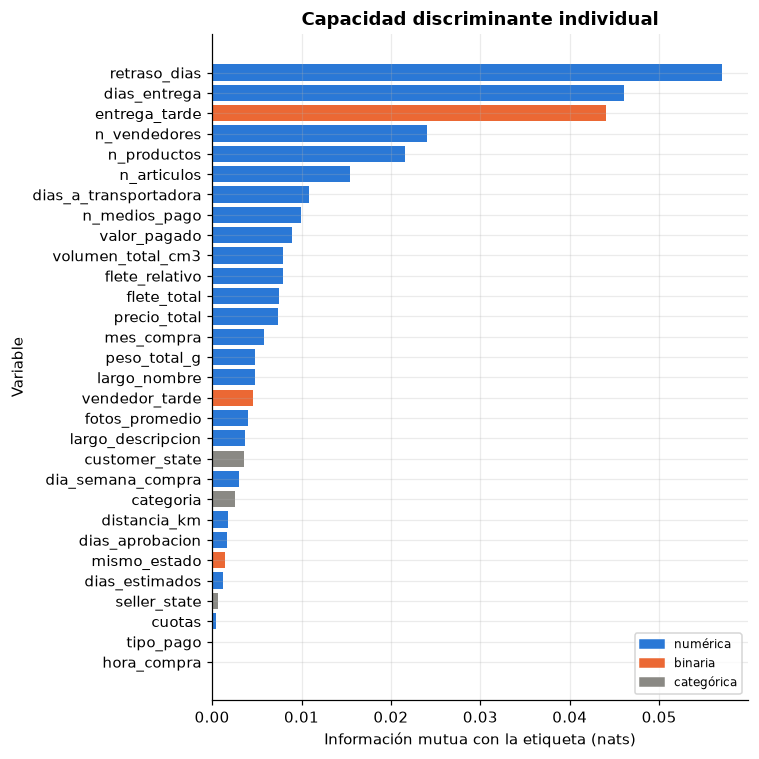

In [5]:
colores_tipo = {"numérica": C_SAT, "binaria": C_INS, "categórica": C_GRIS}
t = individual.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(t.index, t["info_mutua"], color=[colores_tipo[x] for x in t["tipo"]])
ax.set_xlabel("Información mutua con la etiqueta (nats)")
ax.set_ylabel("Variable")
ax.set_title("Capacidad discriminante individual")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=tipo) for tipo, c in colores_tipo.items()], fontsize=8, loc="lower right")
plt.tight_layout(); guardar(fig, "analisis_individual"); plt.show()

In [6]:
corr = Xn[D.NUM].corr(method="spearman")
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("rho").reset_index().query("abs(rho) > 0.8"))
pares

,level_0,level_1,rho
75,precio_total,valor_pagado,0.990


### 1.1 Variables candidatas a eliminar

Marcamos como candidata una variable que cumpla alguna de estas condiciones: información mutua menor que 0,001 nats y, si es numérica o binaria, AUC univariado menor que 0,53; o ser la menos informativa de un par redundante.

In [7]:
UMBRAL_MI, UMBRAL_AUC = 0.001, 0.53
debil = (individual["info_mutua"] < UMBRAL_MI) & ~(individual["auc"] >= UMBRAL_AUC)
candidatas = set(individual.index[debil])
for _, (a, b, _) in pares.iterrows():
    candidatas.add(a if individual.loc[a, "info_mutua"] < individual.loc[b, "info_mutua"] else b)
candidatas = sorted(candidatas, key=lambda v: individual.loc[v, "info_mutua"])
individual.loc[candidatas]

,tipo,info_mutua,auc,cramer_v
variable,,,,
hora_compra,numérica,0.000,0.501,NaN
tipo_pago,categórica,0.000,NaN,0.012
cuotas,numérica,0.000,0.524,NaN
seller_state,categórica,0.001,NaN,0.037
precio_total,numérica,0.007,0.540,NaN


Salen cinco candidatas. La hora de compra, el tipo de pago, las cuotas y el estado del vendedor casi no tienen información sobre la etiqueta. El precio total es redundante con el valor pagado ($\rho_s = 0{,}99$) y tiene algo menos de información mutua. Como el tipo de pago y el estado del vendedor son categóricas codificadas con one-hot, quitarlas elimina 24 de las 79 columnas.

Probamos los dos mejores modelos sin las candidatas para ver si de verdad sobran. Un modelo multivariado puede aprovechar una variable débil en combinación con otras, así que el análisis individual solo sugiere y la validación decide.

In [8]:
resultados = {}
for n in mejores:
    resultados[(n, "original")] = seccion4[n] | {"dim": n_original}
    r = E.validar_configuracion(modelo(n, excluir=candidatas), X_tr, y_tr, X_te, y_te)
    dim = r["modelo"].named_steps["pre"].transform(X_tr.iloc[:5]).shape[1]
    resultados[(n, "selección")] = r | {"dim": dim}
    print(f"{n}: {len(candidatas)} variables menos ({n_original} → {dim} columnas), "
          f"F1 validación {E.formato_ic(*r['validacion']['f1'])} frente a {E.formato_ic(*seccion4[n]['validacion']['f1'])}")

Gradient boosting: 5 variables menos (79 → 55 columnas), F1 validación 0.480 ± 0.008 frente a 0.481 ± 0.008


Bosque aleatorio: 5 variables menos (79 → 55 columnas), F1 validación 0.479 ± 0.008 frente a 0.480 ± 0.008


Sin las cinco variables, ninguno de los dos modelos pierde desempeño: el F1 de validación baja una milésima, muy por dentro del intervalo de confianza. Las candidatas sobraban.

## 2. Extracción lineal: PCA

PCA proyecta las 79 columnas preprocesadas sobre las direcciones de mayor varianza. Como criterio para el número de componentes tomamos el menor número que conserva el 95 % de la varianza del conjunto de entrenamiento. Es un criterio estándar que no mira la etiqueta, de modo que la elección no se ajusta a los datos de validación.

componentes para el 95 % de la varianza: 29 de 79 (63% de reducción)


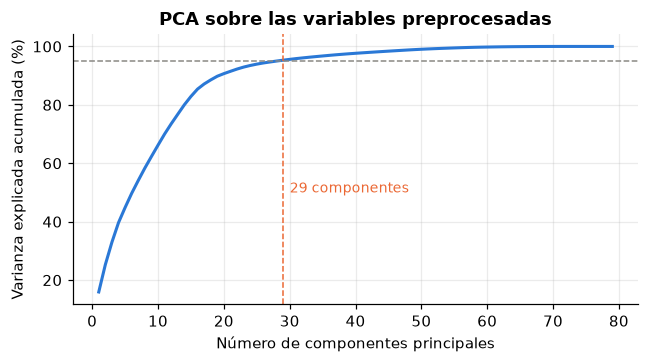

In [9]:
Z = preprocesador().fit_transform(X_tr)
pca = PCA().fit(Z)
acumulada = np.cumsum(pca.explained_variance_ratio_)
n_pca = int(np.searchsorted(acumulada, 0.95) + 1)
print(f"componentes para el 95 % de la varianza: {n_pca} de {n_original} ({1 - n_pca / n_original:.0%} de reducción)")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(np.arange(1, len(acumulada) + 1), 100 * acumulada, color=C_SAT, lw=2)
ax.axhline(95, color=C_GRIS, ls="--", lw=1); ax.axvline(n_pca, color=C_INS, ls="--", lw=1)
ax.text(n_pca + 1, 50, f"{n_pca} componentes", color=C_INS, fontsize=9)
ax.set_xlabel("Número de componentes principales")
ax.set_ylabel("Varianza explicada acumulada (%)")
ax.set_title("PCA sobre las variables preprocesadas")
plt.tight_layout(); guardar(fig, "pca_varianza"); plt.show()

In [10]:
for n in mejores:
    resultados[(n, "PCA")] = E.validar_configuracion(modelo(n, PCA(n_pca, random_state=D.SEMILLA)), X_tr, y_tr, X_te, y_te) | {"dim": n_pca}
    print(f"{n} + PCA({n_pca}): F1 validación {E.formato_ic(*resultados[(n, 'PCA')]['validacion']['f1'])}")

Gradient boosting + PCA(29): F1 validación 0.463 ± 0.010


Bosque aleatorio + PCA(29): F1 validación 0.464 ± 0.006


Con 29 componentes el F1 de validación baja de 0,48 a 0,46 en los dos modelos, y los intervalos ya no se traslapan con los del espacio original. PCA conserva la varianza, no la capacidad de discriminar: buena parte de la varianza está en variables poco informativas como el precio, el peso o las columnas one-hot, y el retraso, que es la variable más útil, queda repartido entre varias componentes. Los ensambles de árboles lo sienten especialmente, porque en el espacio original pueden cortar directo sobre "llegó tarde" y en el espacio de componentes esa condición deja de ser un corte sobre una sola variable.

## 3. Extracción no lineal: UMAP

UMAP construye un grafo de vecinos en el espacio original y busca una representación de menor dimensión que conserve esa estructura local. A diferencia de PCA, no hay una varianza explicada que sirva de criterio, así que elegimos el número de componentes por validación: probamos 2, 5, 10 y 20 componentes con el mejor modelo y nos quedamos con el menor cuyo F1 de validación cae dentro del intervalo de confianza del mejor. Mantenemos los valores por defecto de vecinos (15) y distancia mínima (0,1).

UMAP es costoso en tiempo, así que esta elección se hace con una submuestra estratificada de 20 000 órdenes de entrenamiento. La evaluación de los modelos con el número elegido sí usa todo el entrenamiento.

In [11]:
N_SUB = 20_000
i_sub, _ = train_test_split(np.arange(len(y_tr)), train_size=N_SUB, stratify=y_tr, random_state=D.SEMILLA)
X_sub, y_sub = X_tr.iloc[i_sub], y_tr[i_sub]

DIMS_UMAP = [2, 5, 10, 20]
curva = []
for k in DIMS_UMAP:
    cv = cross_validate(modelo(mejores[0], UMAP(n_components=k, random_state=D.SEMILLA)), X_sub, y_sub,
                        cv=E.pliegues(), scoring={"f1": E.PUNTAJES["f1"]}, n_jobs=5)
    curva.append({"componentes": k, "f1": cv["test_f1"].mean(), "ic": E.semiancho_ic(cv["test_f1"])})
curva = pd.DataFrame(curva)
mejor = curva.loc[curva["f1"].idxmax()]
n_umap = int(curva.loc[curva["f1"] >= mejor["f1"] - mejor["ic"], "componentes"].min())
print("componentes elegidos para UMAP:", n_umap)
curva

componentes elegidos para UMAP: 2


,componentes,f1,ic
0,2,0.340,0.021
1,5,0.324,0.013
2,10,0.325,0.021
3,20,0.327,0.017


El F1 no mejora al agregar componentes. Con 2 se obtiene el valor más alto de la curva y por el criterio fijado es el número elegido. Los valores son mucho más bajos que en el espacio original (0,32 a 0,34 frente a 0,48). Parte de la caída puede venir de usar una submuestra, así que la celda siguiente repite la evaluación con todo el entrenamiento.

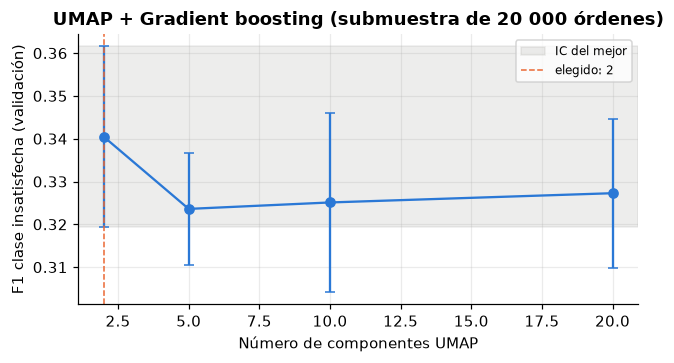

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.errorbar(curva["componentes"], curva["f1"], yerr=curva["ic"], color=C_SAT, marker="o", capsize=3)
ax.axhspan(mejor["f1"] - mejor["ic"], mejor["f1"] + mejor["ic"], color=C_GRIS, alpha=0.15, label="IC del mejor")
ax.axvline(n_umap, color=C_INS, ls="--", lw=1, label=f"elegido: {n_umap}")
ax.set_xlabel("Número de componentes UMAP")
ax.set_ylabel("F1 clase insatisfecha (validación)")
ax.set_title(f"UMAP + {mejores[0]} (submuestra de {N_SUB:,} órdenes)".replace(",", " "))
ax.legend(fontsize=8)
plt.tight_layout(); guardar(fig, "umap_componentes"); plt.show()

In [13]:
for n in mejores:
    resultados[(n, "UMAP")] = E.validar_configuracion(modelo(n, UMAP(n_components=n_umap, random_state=D.SEMILLA)),
                                                      X_tr, y_tr, X_te, y_te, n_jobs=5) | {"dim": n_umap}
    print(f"{n} + UMAP({n_umap}): F1 validación {E.formato_ic(*resultados[(n, 'UMAP')]['validacion']['f1'])}")

Gradient boosting + UMAP(2): F1 validación 0.364 ± 0.017


Bosque aleatorio + UMAP(2): F1 validación 0.371 ± 0.014


UMAP no sirve en este problema. Con el entrenamiento completo los dos modelos quedan en un F1 de validación de 0,36-0,37 y el AUC-ROC en prueba baja a 0,61. UMAP no usa la etiqueta y conserva los vecindarios del espacio de 79 columnas, donde la distancia la dominan las columnas one-hot de categoría y estado y las variables débiles. El retraso es una columna entre 79, así que dos órdenes con el mismo producto y el mismo estado quedan cerca aunque una haya llegado a tiempo y la otra con diez días de retraso.

## 4. Resultados

Para cada modelo y cada espacio de entrada: dimensión, porcentaje de reducción frente a las 79 columnas del preprocesamiento, F1 de validación (media de 5 pliegues con IC del 95 %) y métricas en prueba (IC por bootstrap).

In [14]:
filas = []
for (n, espacio), r in resultados.items():
    p = r["prueba"]
    filas.append({
        "modelo": n, "espacio": espacio, "dimensión": r["dim"],
        "reducción": f"{1 - r['dim'] / n_original:.0%}",
        "F1 validación": E.formato_ic(*r["validacion"]["f1"]),
        "F1 prueba": E.formato_ic(p["f1"][0], bajo=p["f1"][1], alto=p["f1"][2]),
        "AUC-ROC prueba": f"{p['auc_roc'][0]:.3f}",
        "AUC-PR prueba": f"{p['auc_pr'][0]:.3f}",
        "sensibilidad prueba": f"{p['sensibilidad'][0]:.3f}",
        "precisión prueba": f"{p['precision'][0]:.3f}",
    })
tabla5 = pd.DataFrame(filas).set_index(["modelo", "espacio"])
tabla5.to_csv("resultados/seccion5.csv")
tabla5

dimensión reducción  F1 validación  \
modelo            espacio                                         
Gradient boosting original          79        0%  0.481 ± 0.008   
                  selección         55       30%  0.480 ± 0.008   
Bosque aleatorio  original          79        0%  0.480 ± 0.008   
                  selección         55       30%  0.479 ± 0.008   
Gradient boosting PCA               29       63%  0.463 ± 0.010   
Bosque aleatorio  PCA               29       63%  0.464 ± 0.006   
Gradient boosting UMAP               2       97%  0.364 ± 0.017   
Bosque aleatorio  UMAP               2       97%  0.371 ± 0.014   

                                        F1 prueba AUC-ROC prueba  \
modelo            espacio                                          
Gradient boosting original   0.481 [0.463, 0.498]          0.763   
                  selección  0.481 [0.462, 0.498]          0.763   
Bosque aleatorio  original   0.483 [0.466, 0.501]          0.764   
                  selección  0.477 [0.459, 0.494]          0.763   
Gradient boosting PCA        0.469 [0.451, 0.486]          0.755   
Bosque aleatorio  PCA        0.467 [0.449, 0.484]          0.759   
Gradient boosting UMAP       0.388 [0.367, 0.410]          0.612   
Bosque aleatorio  UMAP       0.385 [0.364, 0.406]          0.616   

                            AUC-PR prueba sensibilidad prueba precisión prueba  
modelo            espacio                                                       
Gradient boosting original          0.481               0.445            0.524  
                  selección         0.483               0.437            0.534  
Bosque aleatorio  original          0.483               0.451            0.520  
                  selección         0.481               0.415            0.561  
Gradient boosting PCA               0.458               0.422            0.527  
Bosque aleatorio  PCA               0.463               0.428            0.514  
Gradient boosting UMAP              0.345               0.279            0.635  
Bosque aleatorio  UMAP              0.347               0.286            0.587

La selección de variables es la única reducción que no cuesta desempeño: quita el 30 % de las columnas y el F1 en prueba se mantiene dentro del intervalo de confianza. PCA reduce el 63 % a cambio de una a dos centésimas de F1, y UMAP reduce el 97 % pero pierde casi 0,1. Como modelo final proponemos el gradient boosting con las 25 variables que quedan después de la selección.